In [3]:
# PREGUNTAS
# 1. ¿Cuántos taxis hay y cómo se reparten por tipo de combustible?
# 2. ¿Qué porcentaje de la flota es ECO o cero emisiones?
# 3. ¿Cómo ha cambiado esa proporción a lo largo del tiempo?
# 4. ¿Qué marcas y modelos dominan la flota?
# 5. ¿Qué antigüedad tienen los vehículos?
# 6. ¿Qué modelos concretos lideran en cada tipo de combustible?

In [4]:
import pandas as pd

df = pd.read_csv("datos/300219-1-taxi-flota-csv.csv", sep=";", encoding="latin-1")
df.head()

,Código,Matrícula,Fecha Matriculación,Marca,Modelo,Tipo,Variante,Clasificación medioambiental,Combustible,Cilindrada,Potencia,Número de Plazas,Fecha inicio de prestación del servicio de taxi,Fecha baja vehículo en el servicio de taxi,Eurotaxi,Régimen Especial de Eurotaxi,Fecha inicio Régimen Especial Eurotaxi,Fecha fin Régimen Especial Eurotaxi,Fecha extracción dato
0,523247,M4853VS,16/03/1998,ALFA ROMEO,155,NaN,NaN,C,M: Diesel,NaN,NaN,5,03/08/2012,10/10/2012,NO,NO,NaN,NaN,30/09/2026
1,583326,0041NHN,19/11/2025,BYD,Seal,EKE,SE2R1C,0,BEV: Vehículo eléctrico,NaN,230.0,5,17/12/2025,NaN,NO,NO,NaN,NaN,30/09/2026
2,583538,7371NJK,22/12/2025,BYD,Seal,EKE,SE2R1C,0,BEV: Vehículo eléctrico,NaN,230.0,5,27/01/2026,NaN,NO,NO,NaN,NaN,30/09/2026
3,583466,6464NJP,29/12/2025,BYD,Seal,EKE,SE2R1C,0,BEV: Vehículo eléctrico,NaN,230.0,5,14/01/2026,NaN,NO,NO,NaN,NaN,30/09/2026
4,584812,9225NPR,30/06/2026,BYD,Seal,EKE,SE2R1C,0,BEV: Vehículo eléctrico,NaN,230.0,5,10/07/2026,NaN,NO,NO,NaN,NaN,30/09/2026


In [5]:
print(df.shape)
df.info()

(32376, 19)
<class 'pandas.DataFrame'>
RangeIndex: 32376 entries, 0 to 32375
Data columns (total 19 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Código                                           32376 non-null  int64  
 1   Matrícula                                        32376 non-null  str    
 2   Fecha Matriculación                              32374 non-null  str    
 3   Marca                                            32375 non-null  str    
 4   Modelo                                           32375 non-null  str    
 5   Tipo                                             32341 non-null  str    
 6   Variante                                         32342 non-null  str    
 7   Clasificación medioambiental                     32366 non-null  str    
 8   Combustible                                      32376 non-null  str    
 9   Cilindrada                 

In [6]:
print("Duplicados:", df.duplicated().sum())
print("Duplicados por Código:", df["Código"].duplicated().sum())
print("Sin baja (activos):", df["Fecha baja vehículo en el servicio de taxi"].isnull().sum())
df["Combustible"].value_counts()

Duplicados: 0
Duplicados por Código: 0
Sin baja (activos): 15665


Combustible
HEV: Vehículo híbrido gasolina       15192
M: Diesel                             8403
B: Gasolina/GLP                       4493
M: GNC                                1805
BEV: Vehículo eléctrico               1579
Gasolina transformado a GLP            407
PHEV: Híbrido enchufable gasolina      150
B: Diesel/GLP                           99
Diesel transformado a GLP               82
HEV: Vehículo híbrido diesel            71
B: Gasolina/GNC                         34
M: GLP                                  26
PHEV: Hibrido enchufable diesel         19
M: Gasolina                             13
No especificado                          2
Gasolina transformado a GNC              1
Name: count, dtype: int64

In [7]:
col_baja = "Fecha baja vehículo en el servicio de taxi"
activos = df[df[col_baja].isnull()].copy()
print(activos.shape)
print(activos["Combustible"].value_counts())
print(activos["Clasificación medioambiental"].value_counts())

(15665, 19)
Combustible
HEV: Vehículo híbrido gasolina       11020
BEV: Vehículo eléctrico               1441
B: Gasolina/GLP                       1129
M: GNC                                1068
M: Diesel                              424
Gasolina transformado a GLP            187
PHEV: Híbrido enchufable gasolina      146
B: Diesel/GLP                           84
Diesel transformado a GLP               71
HEV: Vehículo híbrido diesel            63
PHEV: Hibrido enchufable diesel         13
M: GLP                                  11
M: Gasolina                              6
No especificado                          1
Gasolina transformado a GNC              1
Name: count, dtype: int64
Clasificación medioambiental
ECO    13651
0       1595
C        405
B         14
Name: count, dtype: int64


## Respuestas
**Pregunta 1:** La flota activa es de 15665 taxis. El combustible más común es HEV: Vehículo híbrido gasolina con 11020 taxis.

**Pregunta 2:** El 97,3% de la flota tiene etiqueta ECO o 0. Solo el 10,2% tiene etiqueta 0.

In [12]:
df["inicio"] = pd.to_datetime(df["Fecha inicio de prestación del servicio de taxi"], format="%d/%m/%Y", errors="coerce")
df["baja"] = pd.to_datetime(df[col_baja], format="%d/%m/%Y", errors="coerce")
print("Inicio sin fecha:", df["inicio"].isnull().sum())
print("Baja sin fecha:", df["baja"].isnull().sum())
print(df["inicio"].min(), df["inicio"].max())

Inicio sin fecha: 0
Baja sin fecha: 15665
1965-11-19 00:00:00 2026-09-30 00:00:00


In [13]:
print("Inicio antes de 2012:", (df["inicio"] < "2012-01-01").sum())
print("Baja antes de inicio:", (df["baja"] < df["inicio"]).sum())
print(df["inicio"].dt.year.value_counts().sort_index().head(15))

Inicio antes de 2012: 33
Baja antes de inicio: 17
inicio
1965    1
1978    1
1979    1
1986    1
1988    1
1990    1
1992    1
1994    1
1995    1
1996    2
1997    3
1999    1
2004    2
2006    2
2007    3
Name: count, dtype: int64


In [14]:
raras = df[(df["inicio"] < "2012-01-01") | (df["baja"] < df["inicio"])]
print("Filas raras:", len(raras))
raras[["Matrícula", "Marca", "Modelo", "inicio", "baja"]].head(20)

Filas raras: 50


,Matrícula,Marca,Modelo,inicio,baja
337,M7326NT,CITROEN,BX,1992-10-09,NaT
667,4016JVT,CITROEN,C-ELYSEE,2017-01-20,2011-02-01
6501,M2739KN,OPEL,KADETT,1990-01-31,NaT
6502,M0243ST,OPEL,VECTRA,1995-07-21,NaT
6584,M5669XB,PEUGEOT,406,1999-04-30,NaT
6800,1936JKT,PEUGEOT,5008,2016-02-18,2010-03-16
6913,1822JGM,PEUGEOT,5008,2015-09-07,2010-03-16
7429,3861FDM,PEUGEOT,407,2009-07-01,NaT
7502,3335JBL,PEUGEOT,5008,2015-02-02,2013-09-16
7555,M2249PW,RENAULT,R-21,1994-10-31,NaT


In [15]:
viejas = df[df["inicio"] < "2012-01-01"]
print("Viejas sin baja (cuentan como activas):", viejas["baja"].isnull().sum())
print(viejas["Fecha Matriculación"].head(10))

Viejas sin baja (cuentan como activas): 33
337     04/08/1992
6501    13/12/1989
6502    10/07/1995
6584    19/02/1999
7429    31/07/2006
7555    10/10/1994
7709    15/09/1980
7714    07/10/1986
7715           NaN
7716    03/03/1965
Name: Fecha Matriculación, dtype: str


In [16]:
df_serie = df[~(df["baja"] < df["inicio"])].copy()
print("Filas antes:", len(df))
print("Filas para la serie temporal:", len(df_serie))
print("Excluidas:", len(df) - len(df_serie))

Filas antes: 32376
Filas para la serie temporal: 32359
Excluidas: 17


In [17]:
fechas = pd.to_datetime([f"{y}-12-31" for y in range(2012, 2026)] + ["2026-09-30"])
filas = []
for f in fechas:
    en_flota = df_serie[(df_serie["inicio"] <= f) & (df_serie["baja"].isnull() | (df_serie["baja"] > f))]
    n = len(en_flota)
    eco_o_cero = en_flota["Clasificación medioambiental"].isin(["ECO", "0"]).sum()
    cero = (en_flota["Clasificación medioambiental"] == "0").sum()
    filas.append({"fecha": f.date(), "taxis": n, "pct_eco_o_0": round(eco_o_cero / n * 100, 1), "pct_0": round(cero / n * 100, 1)})
evolucion = pd.DataFrame(filas)
evolucion

,fecha,taxis,pct_eco_o_0,pct_0
0,2012-12-31,1807,52.1,0.0
1,2013-12-31,4361,40.8,0.0
2,2014-12-31,6537,36.2,0.0
3,2015-12-31,8767,41.7,0.0
4,2016-12-31,10666,38.6,0.3
5,2017-12-31,12286,39.6,0.3
6,2018-12-31,13592,47.2,0.1
7,2019-12-31,14600,66.2,0.2
8,2020-12-31,15079,71.2,0.3
9,2021-12-31,15338,74.5,1.0


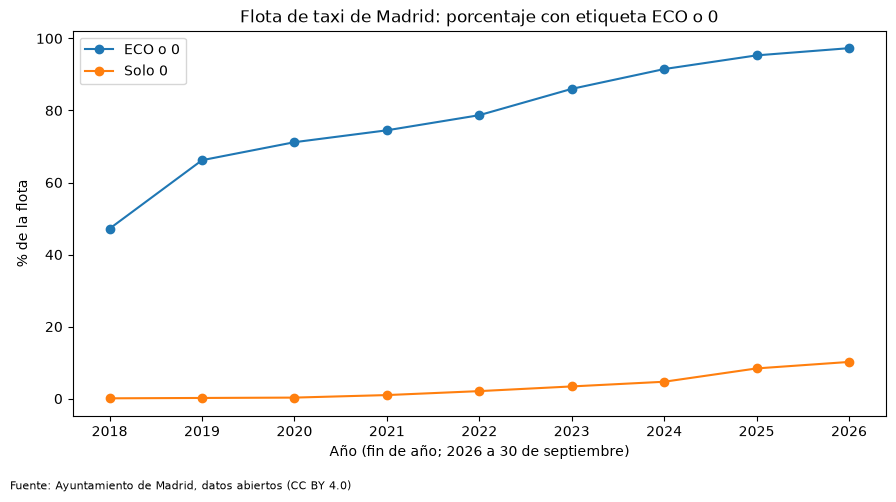

In [18]:
import matplotlib.pyplot as plt

serie = evolucion[evolucion["taxis"] >= 13000]
anios = serie["fecha"].astype(str).str[:4]

plt.figure(figsize=(9, 5))
plt.plot(anios, serie["pct_eco_o_0"], marker="o", label="ECO o 0")
plt.plot(anios, serie["pct_0"], marker="o", label="Solo 0")
plt.title("Flota de taxi de Madrid: porcentaje con etiqueta ECO o 0")
plt.xlabel("Año (fin de año; 2026 a 30 de septiembre)")
plt.ylabel("% de la flota")
plt.legend()
plt.figtext(0.01, 0.01, "Fuente: Ayuntamiento de Madrid, datos abiertos (CC BY 4.0)", fontsize=8)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

Text(0, 0.5, '% de la flota')

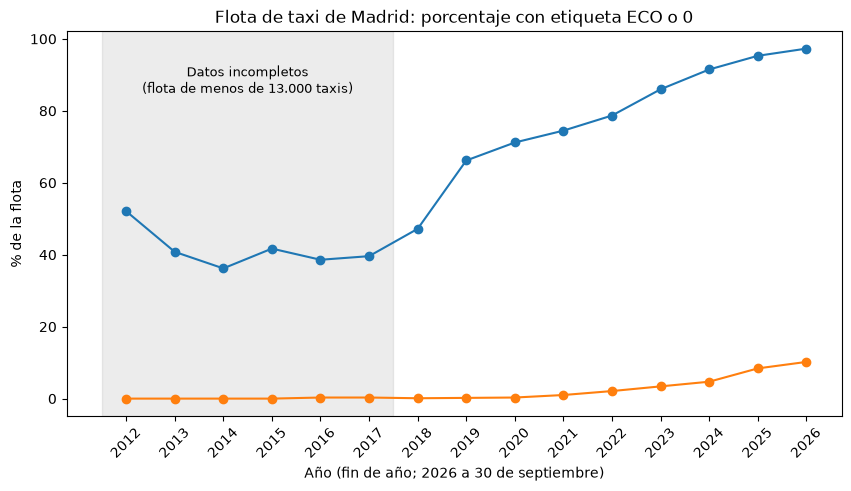

In [22]:
import matplotlib.pyplot as plt

anios = evolucion["fecha"].astype(str).str[:4]
x = list(range(len(evolucion)))

plt.figure(figsize=(10, 5))
plt.axvspan(-0.5, 5.5, color="gray", alpha=0.15)
plt.text(2.5, 85, "Datos incompletos\n(flota de menos de 13.000 taxis)", ha="center", fontsize=9)
plt.plot(x, evolucion["pct_eco_o_0"], marker="o", label="ECO o 0")
plt.plot(x, evolucion["pct_0"], marker="o", label="Solo 0")
plt.xticks(x, anios, rotation=45)
plt.title("Flota de taxi de Madrid: porcentaje con etiqueta ECO o 0")
plt.xlabel("Año (fin de año; 2026 a 30 de septiembre)")
plt.ylabel("% de la flota")


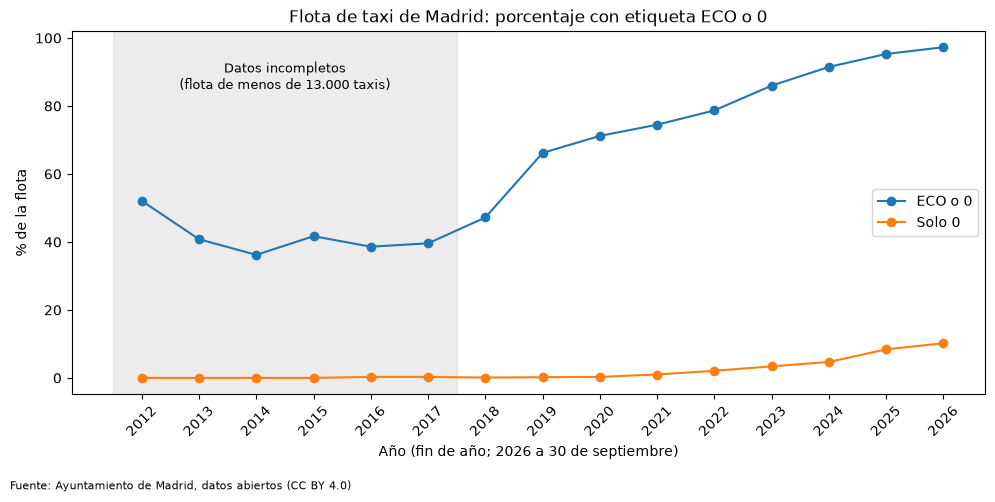

In [23]:
import matplotlib.pyplot as plt

anios = evolucion["fecha"].astype(str).str[:4]
x = list(range(len(evolucion)))

plt.figure(figsize=(10, 5))
plt.axvspan(-0.5, 5.5, color="gray", alpha=0.15)
plt.text(2.5, 85, "Datos incompletos\n(flota de menos de 13.000 taxis)", ha="center", fontsize=9)
plt.plot(x, evolucion["pct_eco_o_0"], marker="o", label="ECO o 0")
plt.plot(x, evolucion["pct_0"], marker="o", label="Solo 0")
plt.xticks(x, anios, rotation=45)
plt.title("Flota de taxi de Madrid: porcentaje con etiqueta ECO o 0")
plt.xlabel("Año (fin de año; 2026 a 30 de septiembre)")
plt.ylabel("% de la flota")
plt.legend(loc="center right")
plt.figtext(0.01, 0.01, "Fuente: Ayuntamiento de Madrid, datos abiertos (CC BY 4.0)", fontsize=8)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("grafico_evolucion.png", dpi=150)
plt.show()

In [24]:
print(activos["Marca"].value_counts().head(10))
print()
print((activos["Marca"] + " " + activos["Modelo"]).value_counts().head(10))

Marca
TOYOTA        10790
DACIA          1094
SEAT            690
TESLA           619
SKODA           571
VOLKSWAGEN      516
FORD            354
HYUNDAI         209
FIAT            189
LEXUS           171
Name: count, dtype: int64

TOYOTA COROLLA SEDAN    5355
TOYOTA PRIUS PLUS       2999
TOYOTA COROLLA TS       1081
TOYOTA COROLLA           724
SEAT LEON ST             628
DACIA JOGGER             580
VOLKSWAGEN CADDY         512
TOYOTA BZ4X              454
DACIA LODGY              441
SKODA OCTAVIA            326
Name: count, dtype: int64


In [25]:
print(activos["Marca"].nunique())
print(sorted(activos["Marca"].dropna().unique()))

21
['BYD', 'CITROEN', 'DACIA', 'FIAT', 'FORD', 'HYUNDAI', 'KGM', 'KIA', 'LEXUS', 'MERCEDES-BENZ', 'NISSAN', 'OPEL', 'PEUGEOT', 'POLESTAR', 'RENAULT', 'SEAT', 'SKODA', 'TESLA', 'TOYOTA', 'VOLKSWAGEN', 'XPENG']


In [26]:
activos["matricula_fecha"] = pd.to_datetime(activos["Fecha Matriculación"], format="%d/%m/%Y", errors="coerce")
fecha_ref = pd.Timestamp("2026-09-30")
activos["edad"] = (fecha_ref - activos["matricula_fecha"]).dt.days / 365.25

print("Sin fecha de matriculación:", activos["matricula_fecha"].isnull().sum())
print("Edad media:", round(activos["edad"].mean(), 1))
print("Edad mediana:", round(activos["edad"].median(), 1))
print("Mayores de 15 años:", (activos["edad"] > 15).sum())
print(activos["edad"].describe().round(1))

Sin fecha de matriculación: 2
Edad media: 4.2
Edad mediana: 3.7
Mayores de 15 años: 28
count    15663.0
mean         4.2
std          2.9
min          0.0
25%          2.0
50%          3.7
75%          6.7
max         61.6
Name: edad, dtype: float64


In [27]:
activos["marca_modelo"] = activos["Marca"] + " " + activos["Modelo"]
tabla = activos.groupby(["Combustible", "marca_modelo"]).size().reset_index(name="taxis")
grandes = activos["Combustible"].value_counts()
grandes = grandes[grandes >= 100].index
tabla = tabla[tabla["Combustible"].isin(grandes)]
tabla = tabla.sort_values(["Combustible", "taxis"], ascending=[True, False])
print(tabla.groupby("Combustible").head(3).to_string(index=False))

                      Combustible         marca_modelo  taxis
                  B: Gasolina/GLP          DACIA LODGY    423
                  B: Gasolina/GLP         DACIA JOGGER    373
                  B: Gasolina/GLP            FIAT TIPO    116
          BEV: Vehículo eléctrico          TOYOTA BZ4X    454
          BEV: Vehículo eléctrico        TESLA MODEL 3    309
          BEV: Vehículo eléctrico        TESLA MODEL Y    303
      Gasolina transformado a GLP            FIAT TIPO     63
      Gasolina transformado a GLP              KGM XLV     50
      Gasolina transformado a GLP TOYOTA COROLLA SEDAN     26
   HEV: Vehículo híbrido gasolina TOYOTA COROLLA SEDAN   5298
   HEV: Vehículo híbrido gasolina    TOYOTA PRIUS PLUS   2975
   HEV: Vehículo híbrido gasolina    TOYOTA COROLLA TS   1043
                        M: Diesel     VOLKSWAGEN CADDY    111
                        M: Diesel    SKODA SKODA RAPID    107
                        M: Diesel          FORD CUSTOM     42
        

In [28]:
print(activos[activos["Marca"] == "SKODA"]["Modelo"].value_counts())
print()
print(activos[activos["Marca"] == "FORD"]["Modelo"].value_counts())

Modelo
OCTAVIA        326
ENYAQ          122
SKODA RAPID    107
Elroq            7
SUPERB           6
RAPID            3
Name: count, dtype: int64

Modelo
MONDEO HIBRIDO          186
CUSTOM                   79
TOURNEO CUSTOM           51
TOURNEO CONNECT          21
FORD TOURNEO CONNECT     11
MUSTANG MACH e            4
TRANSIT CONNECT           2
Name: count, dtype: int64


In [30]:
def quitar_marca(fila):
    modelo = str(fila["Modelo"]).upper().strip()
    marca = str(fila["Marca"]).upper().strip()
    if modelo.startswith(marca + " "):
        modelo = modelo[len(marca) + 1:]
    return modelo

activos["modelo_limpio"] = activos.apply(quitar_marca, axis=1)
print(activos[activos["Marca"] == "SKODA"]["modelo_limpio"].value_counts())
print()
print(activos[activos["Marca"] == "FORD"]["modelo_limpio"].value_counts())

modelo_limpio
OCTAVIA    326
ENYAQ      122
RAPID      110
ELROQ        7
SUPERB       6
Name: count, dtype: int64

modelo_limpio
MONDEO HIBRIDO     186
CUSTOM              79
TOURNEO CUSTOM      51
TOURNEO CONNECT     32
MUSTANG MACH E       4
TRANSIT CONNECT      2
Name: count, dtype: int64


In [31]:
tabla = activos.groupby(["Combustible", "modelo_limpio", "Marca"]).size().reset_index(name="taxis")
grandes = activos["Combustible"].value_counts()
grandes = grandes[grandes >= 100].index
tabla = tabla[tabla["Combustible"].isin(grandes)]
tabla = tabla.sort_values(["Combustible", "taxis"], ascending=[True, False])
print(tabla.groupby("Combustible").head(3).to_string(index=False))

                      Combustible  modelo_limpio      Marca  taxis
                  B: Gasolina/GLP          LODGY      DACIA    423
                  B: Gasolina/GLP         JOGGER      DACIA    373
                  B: Gasolina/GLP           TIPO       FIAT    116
          BEV: Vehículo eléctrico           BZ4X     TOYOTA    454
          BEV: Vehículo eléctrico        MODEL 3      TESLA    309
          BEV: Vehículo eléctrico        MODEL Y      TESLA    303
      Gasolina transformado a GLP           TIPO       FIAT     63
      Gasolina transformado a GLP            XLV        KGM     50
      Gasolina transformado a GLP  COROLLA SEDAN     TOYOTA     26
   HEV: Vehículo híbrido gasolina  COROLLA SEDAN     TOYOTA   5298
   HEV: Vehículo híbrido gasolina     PRIUS PLUS     TOYOTA   2975
   HEV: Vehículo híbrido gasolina     COROLLA TS     TOYOTA   1043
                        M: Diesel          CADDY VOLKSWAGEN    111
                        M: Diesel          RAPID      SKODA   

## Respuestas

**Pregunta 1: ¿Cuántos taxis hay y cómo se reparten por combustible?**
Madrid tiene 15.665 taxis activos (a 30 de septiembre de 2026). Siete de cada diez (70,3%) son híbridos de gasolina. Les siguen los eléctricos (9,2%), los de gasolina/GLP (7,2%) y los de GNC (6,8%). El diésel puro (sin hibridar ni transformar a GLP) es solo el 2,7%.

**Pregunta 2: ¿Qué porcentaje de la flota es ECO o cero emisiones?**
El 97,3% de la flota tiene etiqueta ECO o 0. Pero la etiqueta ECO es muy amplia, así que el dato más exigente es la etiqueta 0, que tiene el 10,2% de los taxis. De esos, De esos, 1.439 son eléctricos, 151 híbridos enchufables y 5 híbridos normales.

**Pregunta 3: ¿Cómo ha cambiado esa proporción con el tiempo?**
Entre 2018 y 2026, los taxis con etiqueta ECO o 0 pasaron del 47,2% al 97,3%, y los de etiqueta 0 del 0,1% al 10,2%. Antes de 2018 el fichero tiene menos de 13.000 taxis, y no es una flota completa, así que no saco conclusiones de esos años.

**Pregunta 4: ¿Qué marcas y modelos dominan?**
Toyota domina la flota: casi 7 de cada 10 taxis (68,9%) son de esta marca. Muy por detrás están Dacia (7,0%) y Seat. El modelo más común es el Corolla Sedan, con 5.355 taxis, y el segundo es el Prius Plus, con 2.999.

**Pregunta 5: ¿Qué antigüedad tienen los vehículos?**
La flota es muy joven: la mitad de los taxis tiene menos de 3,7 años (media de 4,2). Solo 28 vehículos superan los 15 años, y 2 no tienen fecha de matriculación, así que los dejé fuera del cálculo.

**Pregunta 6: ¿Qué modelos lideran en cada tipo de combustible?**
Cada combustible tiene sus propios líderes. En híbrido de gasolina mandan el Corolla Sedan, el Prius Plus y el Corolla TS. En eléctrico lidera el Toyota BZ4X, por delante de Tesla Model 3 y Model Y. En GNC dominan el Seat León ST, el Skoda Octavia y el VW Caddy. En gasolina/GLP lideran el Dacia Lodgy y el Dacia Jogger.

## Conclusiones y limitaciones

**Qué pregunté:** cómo es la flota de taxi de Madrid y cómo ha cambiado en sostenibilidad.

**Datos:** "Taxi. Datos históricos de flota de vehículos", Ayuntamiento de Madrid (datos abiertos), licencia CC BY 4.0, descargado el 29 de octubre de 2026. Cobertura: de enero de 2012 a septiembre de 2026.

**Qué encontré**
- La flota activa es de 15.665 taxis, y el 70,3% son híbridos de gasolina.
- Entre 2018 y 2026 los taxis con etiqueta ECO o 0 pasaron del 47,2% al 97,3%, y los de etiqueta 0 del 0,1% al 10,2%.
- Toyota concentra el 68,9% de la flota. El Corolla Sedan (5.355) y el Prius Plus (2.999) son los modelos más comunes.
- La flota es joven: mediana de 3,7 años.

**Limitaciones**
- Antes de 2018 el fichero tiene muy pocos taxis (1.807 en 2012 frente a unos 15.000 reales). No sé la causa, y no interpreto esos años.
- Había 50 filas con fechas anómalas. Las 17 con baja anterior al inicio las excluí solo de la serie temporal. Las 33 con inicio anterior a 2012 no tienen baja, así que cuentan como activas (0,2% de la flota). No sé por qué figuran como taxis.
- 5 híbridos normales tienen etiqueta 0 y no sé por qué.
- No uní los modelos Corolla (Sedan, TS y sin sufijo) ni Custom y Tourneo Custom, porque los datos no dicen si son el mismo vehículo.
- La tabla de modelos por combustible deja fuera 8 combustibles con menos de 100 taxis (250 taxis en total, el 1,6%).
- 2 vehículos sin fecha de matriculación quedaron fuera del cálculo de edad.
- Estos datos describen la flota, no los viajes ni los ingresos.

**Para profundizar:** datos de viajes o ingresos, el histórico completo anterior a 2018 (preguntar al Ayuntamiento) y cruzar la flota con datos de tráfico o BiciMAD.